# Exercise 4

## Import packages

In [30]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.optim
import torch.utils.data
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.optim.lr_scheduler import StepLR

## Task 1
(3 points)

Implement the training loop for one training epoch.
An epoch trains on the whole training dataset once.

In [31]:
def train(model : torch.nn.Module, use_cuda : bool, train_loader : torch.utils.data.DataLoader, optimizer : torch.optim.Optimizer, epoch : int, log_interval : int):
    """
    Train one epoch
    
    model -- the neural network
    use_cuda -- true if GPU should be used
    train_loader -- data loader
    optimizer -- network optimizer
    epoch -- number of current epoch
    log_interval -- number of training steps between logs
    """
    if(use_cuda):
        model.cuda()
        
    # set the model to train mode
    model.train()
    
    # enumerate over the dataloader to get mini batches
    #       of images and ground truth labels
    # HINT: the builtin python function enumerate() also gives you indices
    for batch_idx, (data, tg_class) in enumerate(train_loader):

        if use_cuda:
            data = data.cuda()
            tg_class = tg_class.cuda()
        
        # set the optimizers gradients to zero
        optimizer.zero_grad()
        
        #  run the network
        out = model(data)
        
        # compute negative log likelihood loss
        l = F.nll_loss(out, tg_class, reduction='sum')
        
        #  do backpropagation
        l.backward()
        
        # Optimize
        optimizer.step()
        
        # print current loss for every nth ("log_interval"th) iteration
        if(batch_idx % log_interval == 0):
            print("Epoch %3d, Batch %4d, b. loss %5f" % (epoch, batch_idx, l))
        

We already implemented the validation function for you (this is essentially validate() from the last exercise)

In [32]:
def validate(model : torch.nn.Module , use_cuda, test_loader):
    """
    Compute test metrics
    
    model -- the neural network
    use_cuda -- true if GPU should be used
    test_loader -- data loader
    """
    # create a 10x10 grid of subplots
    _, axis = plt.subplots(10, 10)
    
    # set model to evaluation mode
    model.eval()
    test_loss = 0
    correct = 0
    plotted = 0
    
    # disable gradients globally
    with torch.no_grad():
        for batch_idx, (data, target) in enumerate(test_loader):
            # for each batch
            if use_cuda:
                # transfer to GPU
                data = data.cuda()
                target = target.cuda()
            
            # run network and compute metrics
            output = model(data)
            test_loss += F.nll_loss(output, target, reduction='sum').item()  # sum up batch loss
            pred = output.argmax(dim=1, keepdim=True)  # get the index of the max log-probability
            
            img_correct = pred.eq(target.view_as(pred))
            correct += pred.eq(target.view_as(pred)).sum().item()
            
            # plot the first 100 images
            img_idx = 0
            data = data.cpu().numpy()
            
            while plotted < 100 and img_idx < data.shape[0]:
                # compute position of ith image in the grid
                y = plotted % 10
                x = plotted // 10
                
                # convert image tensor to numpy array and normalize to [0, 1]
                img = data[img_idx, 0]
                img = (img - np.min(img)) / (np.max(img) - np.min(img))
                
                # make wrongly predicted images red
                img = np.stack([img] * 3, 2)
                if img_correct[img_idx] == 0:
                    img[:, :, 1:] = 0.0
                
                # disable axis and show image
                axis[y][x].axis('off')
                axis[y][x].imshow(img)
                
                # show the predicted class next to each image
                axis[y][x].text(30, 25, pred[img_idx].item())
                
                plotted += 1
                img_idx += 1
            
    test_loss /= len(test_loader.dataset)

    # show results
    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.2f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)))
    plt.show()

## Task 2
(4 points)

Implement a five-layer fully connected neural network.
The dimensions (without batch size) should change like this: 784->200->100->60->30->10
Use log softmax to compute the class predictions.

Run the code at the end of the notebook to train and validate your implementation.

### Task 2.1
* sigmoid non-linear activation function
* note that the last layer does not need an activation function!

### Task 2.2
* add a new class "FCNet2"
* replace sigmoid with ReLU

### Task 2.3
* add a new class "FCNet3"
* add batch normalization to the first and third layers (note the difference between 1D/2D/3D versions)


**NOTE:** The perfomance should improve slightly with each step. However, due to the random weight initialization applied by PyTorch, your results may vary a bit between trainings.

In [33]:
class FCNet1(nn.Module):
    """
    Fully Connected Neural Network
    
    Five fully connected layers with sigmoid non-linearity
    
    Dimensions
    784->200->100->60->30->10
    """
    def __init__(self):
        super(FCNet1, self).__init__()

        # initialize network layers
        # HINT: take a look at "torch.nn" (imported as "nn")
        self.network = nn.Sequential(
            nn.Linear(784, 200),
            nn.Linear(200, 100),
            nn.Linear(100, 60),
            nn.Linear(60, 30),
            nn.Linear(30, 10)
        )
    

    def forward(self, x : torch.Tensor):
        #  reshape batch of images to batch of 1D vectors
        # print(x.shape)
        # print((x.shape[0:-2] + (x.shape[-1] * x.shape[-2],)))
        # x = x.reshape((x.shape[0:-2] + (x.shape[-1] * x.shape[-2],)))
        x = x.flatten(start_dim=1)
        
        #  run network layers
        y = self.network(x)
        
        # compute log softmax over the output
        # HINT: take a look at "torch.nn.functional" (imported as "F")
        output = F.softmax(y, dim = 1)
        
        return output

In [34]:
class FCNet2(nn.Module):
    def __init__(self):
        super(FCNet2, self).__init__()

    def forward(self, x):
        pass

In [35]:
class FCNet3(nn.Module):
    def __init__(self):
        super(FCNet3, self).__init__()
        
    def forward(self, x):
        pass

## Task 3
(3 points)

Implement a convolutional neural network, consisting of two convolutional and two fully connected layers.
This time, the dimensions (without batch size) should change like this: 1x28x28->32x26x26->64x12x12->128->10

### Task 3.1
* two convolutional layers (kernel size 3)
* two fully-connected layers
* ReLU activation function

### Task 3.2
* add batch normalization to first convolutional and first fully connected layer

### Task 3.3
* use max pooling instead of stride to reduce the dimensions to 64x12x12

In [36]:
class ConvNet1(nn.Module):
    """
    Convolutional Neural Network
    
    Two convolutional layers and two fully connected layers
    
    Dimensions:
    1x28x28->32x26x26->64x12x12->128->10
    """
    def __init__(self):
        super(ConvNet1, self).__init__()
        
        self.cnn_layers = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1),
            nn.Conv2d(32, 64, 3, 2)
        )

        self.ann_layers = nn.Sequential(
            nn.Linear(64*12*12, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

        # TODO: initialize network layers
        

    def forward(self, x : torch.Tensor):
        # TODO: run convolutional layers

        x = self.cnn_layers(x)
        
        # TODO: reshape batch of images to batch of 1D vectors
        
        x = torch.flatten(x, start_dim=1)
        
        # TODO: run fully connected layers
       
        output = self.ann_layers(x)

        # TODO: compute log softmax over the output

        output = torch.log_softmax(output, dim=1)       
        
        return output

In [37]:
class ConvNet2(nn.Module):
    """
    Convolutional Neural Network
    
    Two convolutional layers and two fully connected layers
    
    Dimensions:
    1x28x28->32x26x26->64x12x12->128->10
    """
    def __init__(self):
        super(ConvNet2, self).__init__()
        
        self.cnn_layers = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1),
            nn.BatchNorm2d(32),
            nn.Conv2d(32, 64, 3, 2),
        )

        self.ann_layers = nn.Sequential(
            nn.Linear(64*12*12, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

        # TODO: initialize network layers
        

    def forward(self, x : torch.Tensor):
        # TODO: run convolutional layers

        x = self.cnn_layers(x)
        
        # TODO: reshape batch of images to batch of 1D vectors
        
        x = torch.flatten(x, start_dim=1)
        
        # TODO: run fully connected layers
       
        output = self.ann_layers(x)

        # TODO: compute log softmax over the output

        output = torch.log_softmax(output, dim=1)       
        
        return output

In [38]:
class ConvNet3(nn.Module):
    """
    Convolutional Neural Network
    
    Two convolutional layers and two fully connected layers
    
    Dimensions:
    1x28x28->32x26x26->64x12x12->128->10
    """
    def __init__(self):
        super(ConvNet3, self).__init__()
        
        self.cnn_layers = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1),
            nn.BatchNorm2d(32),
            nn.Conv2d(32, 64, 3, 1),
            nn.MaxPool2d(2)
        )

        self.ann_layers = nn.Sequential(
            nn.Linear(64*12*12, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

        # TODO: initialize network layers
        

    def forward(self, x : torch.Tensor):
        # TODO: run convolutional layers

        x = self.cnn_layers(x)
        
        # TODO: reshape batch of images to batch of 1D vectors
        
        x = torch.flatten(x, start_dim=1)
        
        # TODO: run fully connected layers
       
        output = self.ann_layers(x)

        # TODO: compute log softmax over the output

        output = torch.log_softmax(output, dim=1)      
        
        return output

Epoch   1, Batch    0, b. loss 146.664185
Epoch   1, Batch  100, b. loss 15.567514
Epoch   1, Batch  200, b. loss 4.111965
Epoch   1, Batch  300, b. loss 7.826085
Epoch   1, Batch  400, b. loss 8.304390
Epoch   1, Batch  500, b. loss 8.876819
Epoch   1, Batch  600, b. loss 7.952138
Epoch   1, Batch  700, b. loss 4.173265
Epoch   1, Batch  800, b. loss 7.616098
Epoch   1, Batch  900, b. loss 3.651162

Test set: Average loss: 0.0590, Accuracy: 9817/10000 (98.17%)



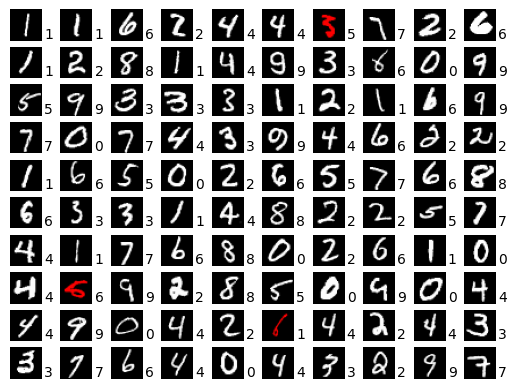

Epoch   2, Batch    0, b. loss 6.182891
Epoch   2, Batch  100, b. loss 1.214825
Epoch   2, Batch  200, b. loss 1.495119
Epoch   2, Batch  300, b. loss 1.713335
Epoch   2, Batch  400, b. loss 0.227655
Epoch   2, Batch  500, b. loss 0.226138
Epoch   2, Batch  600, b. loss 4.556088
Epoch   2, Batch  700, b. loss 3.678726
Epoch   2, Batch  800, b. loss 3.607040
Epoch   2, Batch  900, b. loss 1.642564

Test set: Average loss: 0.0437, Accuracy: 9871/10000 (98.71%)



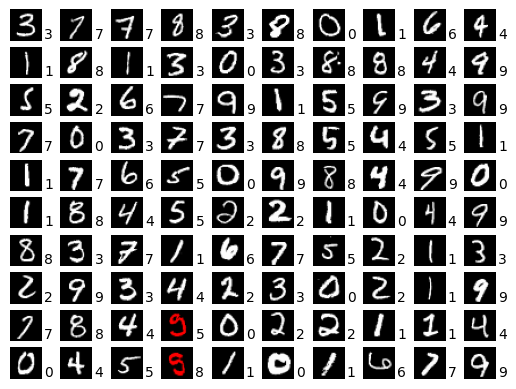

Epoch   3, Batch    0, b. loss 0.345281
Epoch   3, Batch  100, b. loss 1.124961
Epoch   3, Batch  200, b. loss 3.019700
Epoch   3, Batch  300, b. loss 0.462327
Epoch   3, Batch  400, b. loss 2.630527
Epoch   3, Batch  500, b. loss 2.220311
Epoch   3, Batch  600, b. loss 1.138962
Epoch   3, Batch  700, b. loss 0.659612
Epoch   3, Batch  800, b. loss 0.494315
Epoch   3, Batch  900, b. loss 1.118888

Test set: Average loss: 0.0381, Accuracy: 9879/10000 (98.79%)



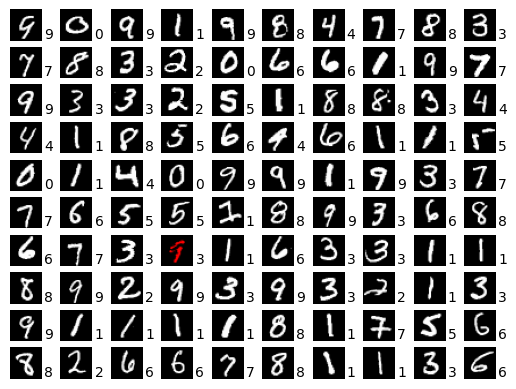

Epoch   4, Batch    0, b. loss 0.147270
Epoch   4, Batch  100, b. loss 0.466589
Epoch   4, Batch  200, b. loss 0.472011
Epoch   4, Batch  300, b. loss 0.112978
Epoch   4, Batch  400, b. loss 0.073035
Epoch   4, Batch  500, b. loss 0.197814
Epoch   4, Batch  600, b. loss 0.022471
Epoch   4, Batch  700, b. loss 3.331191
Epoch   4, Batch  800, b. loss 0.071684
Epoch   4, Batch  900, b. loss 0.303833

Test set: Average loss: 0.0402, Accuracy: 9880/10000 (98.80%)



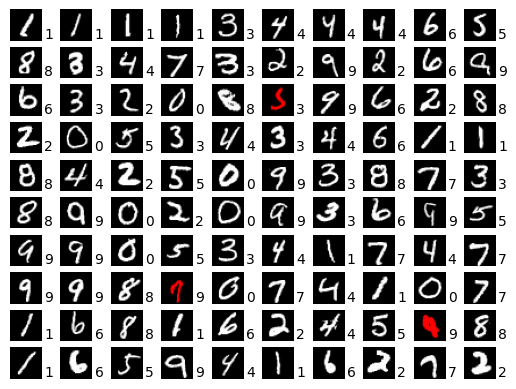

Epoch   5, Batch    0, b. loss 0.079406
Epoch   5, Batch  100, b. loss 0.180062
Epoch   5, Batch  200, b. loss 1.135010
Epoch   5, Batch  300, b. loss 0.309442
Epoch   5, Batch  400, b. loss 0.138598
Epoch   5, Batch  500, b. loss 0.232832
Epoch   5, Batch  600, b. loss 0.127371
Epoch   5, Batch  700, b. loss 0.504017
Epoch   5, Batch  800, b. loss 2.775319
Epoch   5, Batch  900, b. loss 0.117114

Test set: Average loss: 0.0412, Accuracy: 9877/10000 (98.77%)



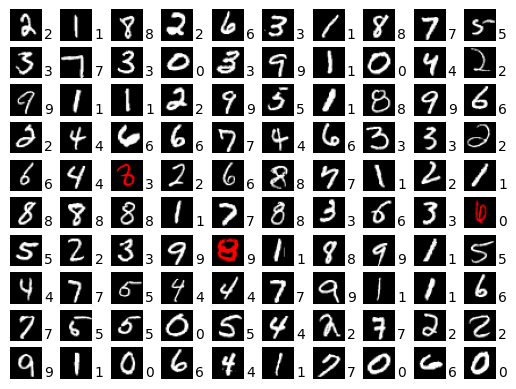

Epoch   6, Batch    0, b. loss 0.375128
Epoch   6, Batch  100, b. loss 1.745480
Epoch   6, Batch  200, b. loss 0.223196
Epoch   6, Batch  300, b. loss 0.161965
Epoch   6, Batch  400, b. loss 0.093892
Epoch   6, Batch  500, b. loss 0.046232
Epoch   6, Batch  600, b. loss 0.362151
Epoch   6, Batch  700, b. loss 0.264494
Epoch   6, Batch  800, b. loss 0.108767
Epoch   6, Batch  900, b. loss 1.824369

Test set: Average loss: 0.0388, Accuracy: 9878/10000 (98.78%)



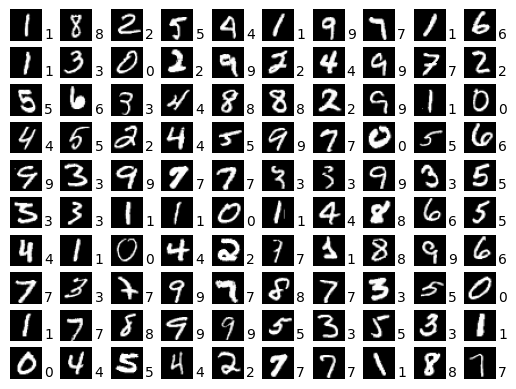

Epoch   7, Batch    0, b. loss 0.007477
Epoch   7, Batch  100, b. loss 1.287538
Epoch   7, Batch  200, b. loss 0.153021
Epoch   7, Batch  300, b. loss 0.479605
Epoch   7, Batch  400, b. loss 0.088951
Epoch   7, Batch  500, b. loss 0.109867
Epoch   7, Batch  600, b. loss 0.066782
Epoch   7, Batch  700, b. loss 0.065817
Epoch   7, Batch  800, b. loss 0.019980
Epoch   7, Batch  900, b. loss 0.060305

Test set: Average loss: 0.0424, Accuracy: 9878/10000 (98.78%)



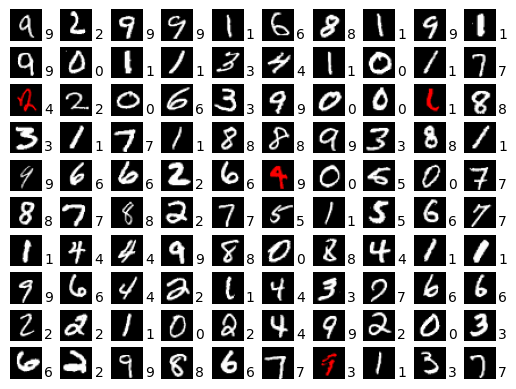

Epoch   8, Batch    0, b. loss 0.083181
Epoch   8, Batch  100, b. loss 0.713571
Epoch   8, Batch  200, b. loss 0.173077
Epoch   8, Batch  300, b. loss 0.034752
Epoch   8, Batch  400, b. loss 0.037763
Epoch   8, Batch  500, b. loss 0.024584
Epoch   8, Batch  600, b. loss 0.026678
Epoch   8, Batch  700, b. loss 0.016634
Epoch   8, Batch  800, b. loss 0.657540
Epoch   8, Batch  900, b. loss 0.133112

Test set: Average loss: 0.0413, Accuracy: 9884/10000 (98.84%)



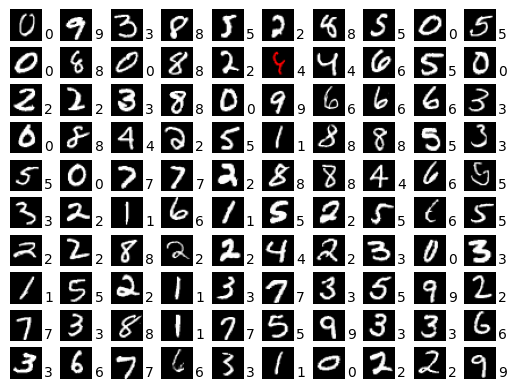

Epoch   9, Batch    0, b. loss 0.020556
Epoch   9, Batch  100, b. loss 0.578653
Epoch   9, Batch  200, b. loss 0.045126
Epoch   9, Batch  300, b. loss 0.066579
Epoch   9, Batch  400, b. loss 0.017013
Epoch   9, Batch  500, b. loss 0.033125
Epoch   9, Batch  600, b. loss 0.022695
Epoch   9, Batch  700, b. loss 0.108430
Epoch   9, Batch  800, b. loss 0.019229
Epoch   9, Batch  900, b. loss 0.028255

Test set: Average loss: 0.0423, Accuracy: 9876/10000 (98.76%)



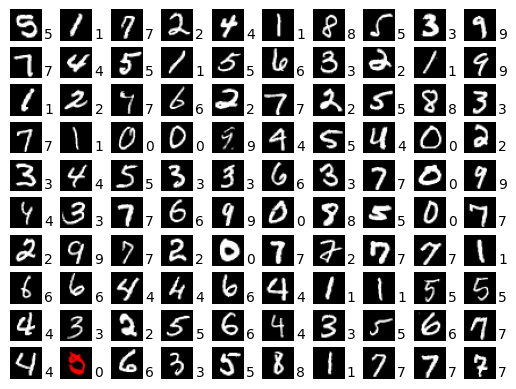

Epoch  10, Batch    0, b. loss 0.065056
Epoch  10, Batch  100, b. loss 0.018971
Epoch  10, Batch  200, b. loss 0.073586
Epoch  10, Batch  300, b. loss 0.083500
Epoch  10, Batch  400, b. loss 0.143727
Epoch  10, Batch  500, b. loss 0.100104
Epoch  10, Batch  600, b. loss 0.004914
Epoch  10, Batch  700, b. loss 0.046226
Epoch  10, Batch  800, b. loss 0.036912
Epoch  10, Batch  900, b. loss 0.005390

Test set: Average loss: 0.0426, Accuracy: 9884/10000 (98.84%)



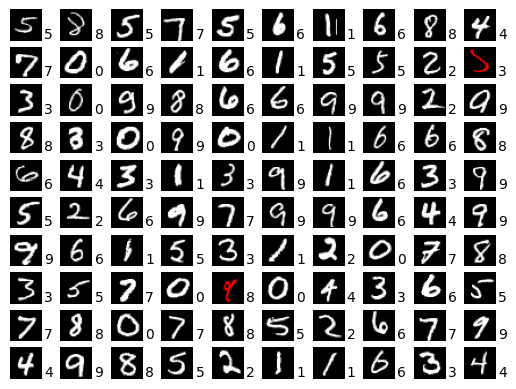

In [39]:
# hyper parameters
batch_size = 64
test_batch_size = 1000
epochs = 10
lr = 1.0
gamma = 0.7
log_interval = 100

# use GPU if available
#use_cuda = torch.cuda.is_available()
use_cuda = False
kwargs = {'num_workers': 1, 'pin_memory': True} if use_cuda else {}

# initialize data loaders
train_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=True, download=True,
    transform=transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])), batch_size=batch_size, shuffle=True, **kwargs)

test_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=False, 
    transform=transforms.Compose([
        transforms.ToTensor(), 
        transforms.Normalize((0.1307,), (0.3081,))
    ])),
    batch_size=test_batch_size, shuffle=True, **kwargs)

model = ConvNet3()
if use_cuda:
    model = model.cuda()

# initialize optimizer and scheduler
optimizer = optim.Adadelta(model.parameters(), lr=lr)
scheduler = StepLR(optimizer, step_size=1, gamma=gamma)

for epoch in range(1, epochs + 1):
    # train one epoch
    train(model, use_cuda, train_loader, optimizer, epoch, log_interval)
    
    # run on test dataset
    validate(model, use_cuda, test_loader)
    scheduler.step()
    
    torch.save(model.state_dict(), "models/mnist/checkpoint.pt")